# Person 1: Evidence and Objective

**Question:** Does pair-vote expansion overcount long reads, and does normalization improve phasing recovery?

| Plan item | Implementation | Evaluation |
|---|---|---|
| A: Baseline | Complete | Supplied reads + synthetic grid |
| B1: Per-read normalization | Complete | Same datasets |
| B2: Per-site normalization | Complete | Same datasets |
| C: Exact-row deduplication | Complete | Same datasets |
| D: Full-read MEC | Complete; classical only | Same datasets |
| Evidence | 72 settings x 200 replicates | Truth metrics, ties, 95% CIs |
| Team hand-off | Graph API, datasets, seeds, CSVs, plots | Local outputs; team alignment pending |

**Controls:** Five SNPs; identical reads/seeds across variants; exact enumeration. Change one objective rule at a time. Evaluate against hidden truth, not each objective's own cost. Average over all minimizing candidates; never use truth to choose one. Negative results are retained. No quantum execution or advantage claims.

**Code:** `objective_study.py`. Results are written to `objective_results/`.

In [1]:
import sys
import os
import json
import importlib.metadata as metadata
from pathlib import Path
import numpy as np
from IPython.display import display, Image

DOCS = Path.cwd() if (Path.cwd() / "objective_study.py").exists() else Path.cwd() / "docs"
if str(DOCS) not in sys.path:
    sys.path.insert(0, str(DOCS))
from objective_study import (
    VARIANTS, baseline_weight, per_read_weight, per_site_weight,
    build_graph, all_states, mec_scores, objective_scores,
    evaluate, optimal_mask, score_metrics, generate_reads,
    make_manifest, run_study, summarize, write_csv, plot_results,
)
OUT = DOCS / "objective_results"
OUT.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(DOCS.parent / ".venv-objectives" / "matplotlib-cache"))
print("Python:", sys.version.split()[0])

Python: 3.14.10


## Supplied reads

Rows are reads; columns are SNPs; `-1` denotes missing calls.

In [2]:
READS = np.array([[0,1,1,-1,-1], [1,0,0,-1,-1],
                  [-1,1,1,0,-1], [-1,0,0,1,-1],
                  [-1,-1,1,0,1], [-1,-1,0,1,0],
                  [0,-1,-1,0,1], [1,-1,-1,1,0],
                  [0,0,-1,-1,-1]])
states = all_states(READS.shape[1])
print(READS)

[[ 0  1  1 -1 -1]
 [ 1  0  0 -1 -1]
 [-1  1  1  0 -1]
 [-1  0  0  1 -1]
 [-1 -1  1  0  1]
 [-1 -1  0  1  0]
 [ 0 -1 -1  0  1]
 [ 1 -1 -1  1  0]
 [ 0  0 -1 -1 -1]]


## A. Baseline

Each observed pair receives weight 1. Return `(A, D, J, c0)` with upper-triangular matrices; `J=(D-A)/2`.

In [3]:
A, D, J, c0 = build_graph(READS, baseline_weight)
print("A (same):\n", A)
print("D (opposite):\n", D)

A (same):
 [[0. 1. 0. 2. 0.]
 [0. 0. 4. 0. 0.]
 [0. 0. 0. 0. 2.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
D (opposite):
 [[0. 2. 2. 0. 2.]
 [0. 0. 0. 2. 0.]
 [0. 0. 0. 4. 0.]
 [0. 0. 0. 0. 4.]
 [0. 0. 0. 0. 0.]]


## B1. Per-read normalization

For L observed SNPs, each pair receives `2 / (L*(L-1))`. Total weight per read is 1. Reads with fewer than two observed SNPs contribute no pairs.

In [4]:
A1, D1, J1, c1 = build_graph(READS, per_read_weight)
print("B1 pair weight for L=3:", per_read_weight(3))

B1 pair weight for L=3: 0.3333333333333333


## B2. Per-site normalization

Each pair receives `1 / (L-1)`. Each observed site has total incident weight 1; the total edge weight per read is L/2. This is a separate variant, not combined with B1.

In [5]:
A2, D2, J2, c2 = build_graph(READS, per_site_weight)
print("B2 pair weight for L=3:", per_site_weight(3))

B2 pair weight for L=3: 0.5


## C. Deduplicated reads

Collapse exactly identical rows, then apply baseline weights. Do not combine with normalization. Identical rows can be independent observations; this rule may discard useful support.

In [6]:
unique_reads = np.unique(READS, axis=0)
Ac, Dc, Jc, cc = build_graph(unique_reads)
print("Original / unique read counts:", len(READS), len(unique_reads))

Original / unique read counts: 9 9


## D. Full-read MEC (classical reference)

For each read, let d be the mismatches to candidate x at its L observed sites. MEC contributes `min(d, L-d)`; baseline pairwise voting contributes `d*(L-d)`. Missing calls are ignored. MEC is not passed to the pairwise Ising/QAOA pipeline.

In [7]:
mec = mec_scores(states, READS)
print("Minimum MEC:", mec.min())

Minimum MEC: 1.0


## Checks

Manual weights, independent per-read scoring, complement symmetry, Ising equality, tie policy, and noiseless truth consistency.

In [8]:
tiny = np.array([[0, 1, 1], [0, 0, -1], [-1, -1, 0]])
ta, td, _, _ = build_graph(tiny, per_read_weight)
assert np.isclose(ta[0, 1], 1)
assert np.isclose(ta[1, 2], 1/3)
assert np.isclose(td[0, 1], 1/3)
assert np.isclose(td[0, 2], 1/3)
assert np.isclose((ta + td).sum(), 2)
for weight in (baseline_weight, per_read_weight, per_site_weight):
    for length in (2, 3, 4, 5):
        read = np.zeros((1, length), dtype=int)
        a, d, _, _ = build_graph(read, weight)
        expected = length*(length-1)/2 * weight(length)
        assert np.isclose((a+d).sum(), expected)

rng = np.random.default_rng(104)
check_reads = rng.integers(-1, 2, size=(12, 5))
scores, graphs = objective_scores(check_reads, states)
for name, graph in graphs.items():
    a, d, j, offset = graph
    z = 1 - 2*states
    ising = offset + sum(j[i,k]*z[:,i]*z[:,k]
                         for i in range(5) for k in range(i+1,5))
    assert np.allclose(ising, scores[name])
    assert np.allclose(scores[name], scores[name][::-1])
for candidate, actual_pairwise, actual_mec in zip(states, scores[VARIANTS[0]], scores[VARIANTS[4]]):
    expected_pairwise = expected_mec = 0
    for read in check_reads:
        observed = read != -1
        length = int(observed.sum())
        mismatches = int(np.sum(candidate[observed] != read[observed]))
        expected_pairwise += mismatches*(length-mismatches)
        expected_mec += min(mismatches, length-mismatches)
    assert np.isclose(actual_pairwise, expected_pairwise)
    assert np.isclose(actual_mec, expected_mec)
truth = np.array([0,1,1,0,1])
empty_scores, _ = objective_scores(np.full((2,5), -1), states)
for costs in empty_scores.values():
    metrics = score_metrics(states, costs, truth)
    assert metrics['tied_phasings'] == 16
    assert np.isclose(metrics['recovery'], 1/16)
    assert metrics['truth_is_optimal'] == 1 and metrics['unique_truth'] == 0
for seed in range(5):
    reads = generate_reads(truth, 12, 'mixed', 0.0, 0.25, seed)
    for costs in objective_scores(reads, states)[0].values():
        assert score_metrics(states, costs, truth)['truth_is_optimal'] == 1
assert evaluate(truth, truth)['hamming_errors'] == 0
assert evaluate(1-truth, truth)['hamming_errors'] == 0
assert np.array_equal(generate_reads(truth, 12, 'mixed', 0.1, 0.25, 17),
                      generate_reads(truth, 12, 'mixed', 0.1, 0.25, 17))
assert np.allclose(objective_scores(check_reads, states)[0][VARIANTS[3]],
                   objective_scores(np.concatenate([check_reads, check_reads]), states)[0][VARIANTS[3]])
print("All checks passed.")

All checks passed.


## Exact comparison on the supplied reads

Raw cost magnitudes are not comparable between objectives.

In [9]:
supplied_scores, _ = objective_scores(READS, states)
for name, costs in supplied_scores.items():
    winners = states[optimal_mask(costs)]
    print(name, "| minimum:", round(float(costs.min()), 6),
          "| candidates:", ["".join(map(str,x)) for x in winners])

A baseline | minimum: 1.0 | candidates: ['01101', '10010']
B1 per-read | minimum: 1.0 | candidates: ['01101', '10010']
B2 per-site | minimum: 1.0 | candidates: ['01101', '10010']
C deduplicated | minimum: 1.0 | candidates: ['01101', '10010']
D MEC | minimum: 1.0 | candidates: ['01101', '10010']


## Experiment grid

3 length distributions (short / mixed / long), 4 per-call error rates (0, 2, 5, 10%), 2 missing rates (0, 25%), 3 read counts (6, 12, 24), 200 replicates per setting. Intervals are contiguous before independent missingness. All variants use identical data. The generator models IID reads, not PCR duplicates.

The same 200 replicate seeds are reused across settings. Saved datasets and manifest are the proposed hand-off to teammates; coordinate before combining with other tracks.

Metrics: Hamming error modulo complement; exact recovery under uniform tie breaking; truth in the optimal set; unique truth; number of optimal phasings; competition rank of truth modulo complement. CIs are per-setting replicate-level estimates, not shot uncertainty.

In [10]:
manifest = make_manifest(repeats=200)
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
rows, disagreements = run_study(manifest, output_dir=OUT)
summary = summarize(rows)
write_csv(OUT / "replicate_metrics.csv", rows)
write_csv(OUT / "variant_summary.csv", summary)
(OUT / "disagreements.json").write_text(json.dumps(disagreements, indent=2) + "\n", encoding="utf-8")
versions = {name: metadata.version(name) for name in ("numpy", "matplotlib", "ipykernel")}
(OUT / "environment.json").write_text(json.dumps({"python": sys.version, **versions}, indent=2) + "\n", encoding="utf-8")
print("Datasets:", len(manifest["settings"]) * manifest["repeats"])
print("Method evaluations:", len(rows))

Datasets: 14400
Method evaluations: 72000


## Accuracy versus length and error rate

Fixed slice: 12 reads and no missing calls. Error bars are approximate 95% CIs of replicate-level recovery probabilities. Full settings are retained in CSV.

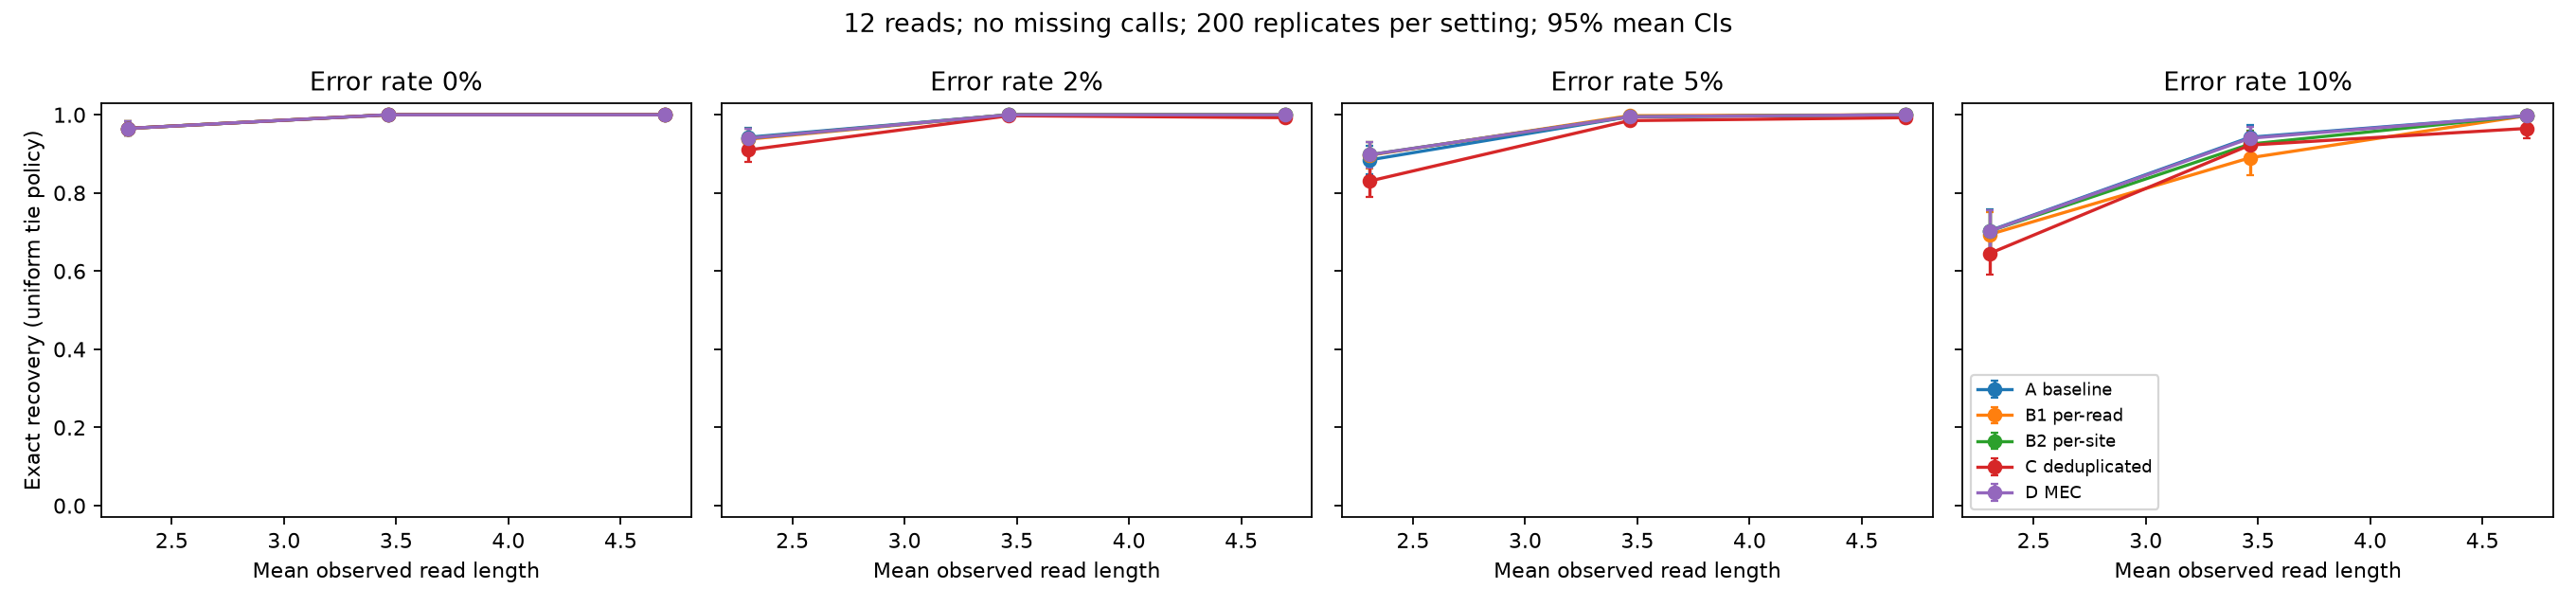

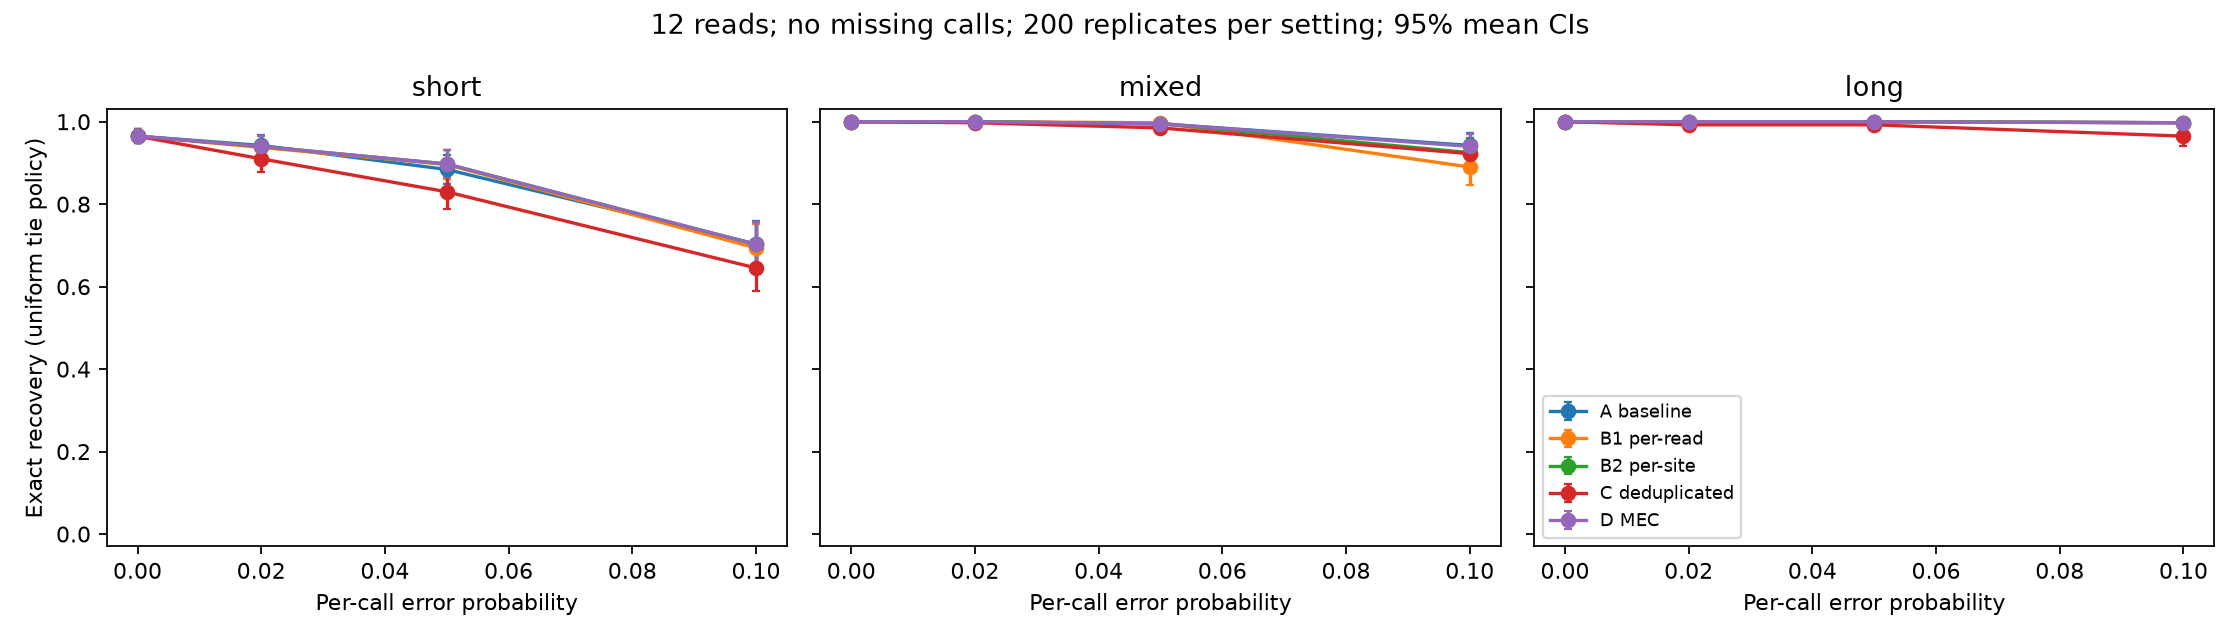

In [11]:
plot_results(summary, OUT)
display(Image(filename=str(OUT / "accuracy_vs_length.png")))
display(Image(filename=str(OUT / "accuracy_vs_error.png")))

## Disagreement inspection

The JSON retains all candidate scores for up to 12 A/B1 disagreements. Inspect observed calls, truth, and all minimizing states; no winner is selected with truth.

In [12]:
if disagreements:
    case = disagreements[0]
    print("Setting:", case["setting_id"], "replicate:", case["replicate"])
    print("Truth:", case["truth"])
    print("Reads:\n", np.array(case["reads"]))
    for name, winners in case["optima"].items():
        costs = np.array(case["scores"][name])
        metrics = score_metrics(states, costs, np.array(case["truth"]))
        print(name, "| optima:", winners, "| expected Hamming:", metrics["mean_hamming"])
    # Deterministic representatives, chosen without looking at truth.
    chosen = {name: np.array(case["optima"][name][0]) for name in VARIANTS[:2]}
    print("Per-read contributions: row, L, A(xA), A(xB1), B1(xA), B1(xB1)")
    for index, read in enumerate(np.array(case["reads"])):
        observed = read != -1
        length = int(observed.sum())
        penalties = []
        for candidate in chosen.values():
            d = int(np.sum(candidate[observed] != read[observed]))
            penalties.append(d*(length-d))
        print(index + 1, length, *penalties,
              *[round(value * per_read_weight(length), 3) for value in penalties])

else:
    print("No A/B1 disagreements in this grid.")


Setting: 6 replicate: 5
Truth: [1, 1, 0, 1, 0]
Reads:
 [[-1 -1  0  1  0]
 [-1 -1  1  0  1]
 [-1 -1 -1  0  1]
 [ 1  1  0 -1 -1]
 [ 1  0 -1 -1 -1]
 [-1 -1  0  1 -1]]
A baseline | optima: [[0, 0, 1, 0, 1], [1, 1, 0, 1, 0]] | expected Hamming: 0.0
B1 per-read | optima: [[0, 1, 0, 1, 0], [0, 1, 1, 0, 1], [1, 0, 0, 1, 0], [1, 0, 1, 0, 1]] | expected Hamming: 1.0
B2 per-site | optima: [[0, 0, 1, 0, 1], [0, 1, 0, 1, 0], [0, 1, 1, 0, 1], [1, 0, 0, 1, 0], [1, 0, 1, 0, 1], [1, 1, 0, 1, 0]] | expected Hamming: 0.6666666666666666
C deduplicated | optima: [[0, 0, 1, 0, 1], [1, 1, 0, 1, 0]] | expected Hamming: 0.0
D MEC | optima: [[0, 0, 1, 0, 1], [0, 1, 0, 1, 0], [0, 1, 1, 0, 1], [1, 0, 0, 1, 0], [1, 0, 1, 0, 1], [1, 1, 0, 1, 0]] | expected Hamming: 0.6666666666666666
Per-read contributions: row, L, A(xA), A(xB1), B1(xA), B1(xB1)
1 3 0 0 0.0 0.0
2 3 0 0 0.0 0.0
3 2 0 0 0.0 0.0
4 3 0 2 0.0 0.667
5 2 1 0 1.0 0.0
6 2 0 0 0.0 0.0


## Conclusions

Weighting can change the optimal reconstruction, but normalization does not consistently improve recovery in the tested synthetic settings. Results are limited to five SNPs and the specified generator.

See [conclusion.md](objective_results/conclusion.md) for the detailed results and limitations. This document is maintained separately; rerunning the notebook does not overwrite it.

## Team hand-off and attribution

- `objective_study.py`: `build_graph(reads, weight_fn) -> (A,D,J,c0)`, generator, exact metrics, MEC reference.
- `objective_results/manifest.json`: settings, explicit seeds, and tie policy.
- `objective_results/datasets.npz`: `reads_<setting_id>` and `truth_<setting_id>` arrays, indexed by replicate.
- CSVs: replicate metrics and setting-level means/CIs; JSON: disagreement cases; PNGs and Markdown: presentation evidence.
- QAOA: use the chosen weighted graph; recompute its exact reference and retrain. Keep MEC classical. Do not compare raw costs across objectives.
- Team integration and a reviewed B1/B2 preference remain pending; no hardware or QAOA work was performed here.

**Disclosure:** Supplied reads and baseline logic originate in the team starter notebook. Variants, synthetic generator, metrics, notebook and analysis were prepared with AI assistance. The author must review the results and disclose assistance in the final submission.